# Calidad de la telemetría: 200 bicis antes de analizar nada

**Avanzado · Jornada 1 · Bloque 1.2 · diapositivas seis-defectos, hueco-pico, imposibles, cambio-hora, imputar y ejercicio-calidad**

¿Qué bicis se pueden usar tal cual, cuáles hay que limpiar y cuáles hay que dejar fuera?
Se construye un informe de calidad por bici (completitud, duplicados, saltos y días parada) y se
clasifica cada una como apta, recuperable o descartable.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

Tenemos la telemetría de 200 bicis (BC-0001 a BC-0200) del 1 de octubre de 2025 al 31 de marzo
de 2026, **tal como llega**: con duplicados, filas fuera de orden, huecos y reinicios del
odómetro. Seis meses que incluyen, a propósito, los dos cambios de hora.

Antes de calcular un solo kilómetro, hay que saber qué bicis son de fiar.

> **Mensaje clave del bloque:** un indicador de calidad por registro vale más que una limpieza silenciosa.

In [2]:
# Ayudas de formato en español: números, porcentajes, fechas y ejes.


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha como en las diapositivas: 18-5-2026."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"


import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def eje_es(ax, eje="y", decimales=0, sufijo=""):
    """Etiquetas de un eje con números en español."""
    formato = FuncFormatter(lambda v, _: n(v, decimales) + sufijo)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)


def eje_meses(ax, meses=(1, 4, 7, 10)):
    """Eje de fechas con el mes en español: «ene 2026»."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=meses))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{MESES[mdates.num2date(v).month - 1]} {mdates.num2date(v).year}"))

## 1. Cargar y mirar los datos

In [3]:
muestra = pd.read_parquet(DATOS / "telemetria" / "muestra_200_bicis.parquet")
muestra["bici_id"] = muestra["bici_id"].astype(str)   # texto: agrupa igual en pandas 2 y 3
muestra["estado"] = muestra["estado"].astype(str)
bicis = pd.read_csv(DATOS / "telemetria" / "bicis.csv")   # lote del módulo de cada bici

print("Lecturas:", n(len(muestra)), "· Bicis:", muestra["bici_id"].nunique())
muestra.head()

Lecturas: 864.895 · Bicis: 200


,bici_id,ts_utc,odometro_km,bateria_pct,lat,lon,estado
0,BC-0001,2025-09-30 22:00:07+00:00,1300.4,100,40.021091,-12.521354,servicio
1,BC-0001,2025-09-30 23:00:18+00:00,1300.4,100,40.021002,-12.521040,servicio
2,BC-0001,2025-10-01 00:00:14+00:00,1300.4,100,40.020861,-12.521118,servicio
3,BC-0001,2025-10-01 01:00:07+00:00,1300.4,100,40.021053,-12.521412,servicio
4,BC-0001,2025-10-01 02:00:05+00:00,1300.4,98,40.020993,-12.521314,servicio


Cada fila es un mensaje: la hora en UTC, el odómetro **acumulado** (solo crece, como el
cuentakilómetros de un coche), la batería, la posición y si la bici está en servicio o en el
taller. El fichero está en el **orden de llegada**, no ordenado por hora.

## 2. Un hueco y un reinicio: la bici BC-0042

Lo que hace todo el mundo con un acumulado es diferenciar: restar cada lectura de la anterior.
Veamos qué pasa con una semana de BC-0042 (diapositiva `hueco-pico`).

In [4]:
ej = pd.read_csv(DATOS / "telemetria" / "bici_ejemplo_7_dias.csv")
ej["ts_utc"] = pd.to_datetime(ej["ts_utc"], utc=True)
ej = ej.sort_values("ts_utc").reset_index(drop=True)

ej["km"] = ej["odometro_km"].diff()                              # lo ingenuo
ej["horas"] = ej["ts_utc"].diff().dt.total_seconds() / 3600      # tiempo real entre lecturas
ej["hora_local"] = bici.hora_local(ej["ts_utc"]).dt.strftime("%d-%m-%Y %H:%M")

# Las dos filas raras: la que llega tras el hueco y el reinicio.
ej.loc[[ej["horas"].idxmax(), ej["km"].idxmin()], ["hora_local", "odometro_km", "km", "horas"]]

,hora_local,odometro_km,km,horas
58,12-11-2025 16:00,3109.3,5.3,7.003056
98,14-11-2025 08:00,8.1,-3198.5,0.997500


- Tras el hueco, una sola fila trae **5,3 km**: no son los de una hora, son los de **siete horas
  juntas**. En una bici muy usada sería un pico falso de 20 o 30 km «en una hora».
- El reinicio: el odómetro vuelve a 0 y la diferencia sale **−3.198 km**. Si sumáis los
  kilómetros del mes, esa fila se come todo lo demás.

La regla: ordenar por la hora del mensaje, quitar duplicados, **mirar el tiempo que pasa entre
lecturas** y tratar aparte cualquier salto negativo.

### Imputar dejando rastro

Ahora lo arreglamos como dice la diapositiva `imputar`: una fila por hora, y una columna que diga
de dónde sale cada valor (medido, repartido o hueco).

In [5]:
max_horas_repartir = 12   # ← huecos más largos no se rellenan: se dejan y se marcan

# Rejilla de horas en UTC: una fila por hora, haya mensaje o no.
ej["hora_utc"] = ej["ts_utc"].dt.floor("h")
rejilla = pd.date_range(ej["hora_utc"].min(), ej["hora_utc"].max(), freq="h")
odometro = ej.set_index("hora_utc")["odometro_km"].reindex(rejilla)

km = odometro.diff()
origen = pd.Series("medido", index=rejilla)
origen[odometro.isna()] = "hueco"

# Reinicio: el odómetro volvió a 0, así que lo recorrido desde entonces es la propia lectura.
reinicio = km < -1
km[reinicio] = odometro[reinicio]

# Huecos cortos: el acumulado dice cuánto subió, no cuándo. Se reparte a partes iguales.
sin_dato = odometro.isna()
id_hueco = (sin_dato != sin_dato.shift()).cumsum()[sin_dato]
for _, horas in id_hueco.groupby(id_hueco):
    antes = horas.index[0] - pd.Timedelta(hours=1)
    despues = horas.index[-1] + pd.Timedelta(hours=1)
    if len(horas) > max_horas_repartir or despues not in odometro.index:
        continue
    tramo = horas.index.append(pd.DatetimeIndex([despues]))
    km[tramo] = (odometro[despues] - odometro[antes]) / len(tramo)
    origen[tramo] = "repartido"

limpia_042 = pd.DataFrame({"odometro_km": odometro, "km": km.round(2), "origen": origen})
print(limpia_042["origen"].value_counts().to_string())
print("km de la semana, diferenciando a lo bruto:", n(ej["km"].sum(), 1))
print("km de la semana, con reinicio y reparto:  ", n(limpia_042["km"].sum(), 1))

origen
medido       161
repartido      7
km de la semana, diferenciando a lo bruto: −2.852,8
km de la semana, con reinicio y reparto:   353,8


Misma semana, dos sumas: a lo bruto la bici «recorre» miles de kilómetros negativos; con el
reinicio tratado y el hueco repartido, recorre lo que de verdad recorrió. Y cada fila dice de
dónde sale su valor: dentro de seis meses alguien preguntará por qué BC-0042 hizo tantos
kilómetros un miércoles, y la respuesta estará en los datos.

## 3. Los defectos, uno a uno, en las 200 bicis

Cuatro indicadores por bici, como pide el ejercicio. Primero, lo que se ve **en el orden de llegada**.

In [6]:
filas = muestra.groupby("bici_id").size()

# Fuera de orden: una fila con hora anterior a la que llegó justo antes (en la misma bici).
retroceso = muestra.groupby("bici_id")["ts_utc"].diff().dt.total_seconds() < 0
fuera_de_orden = retroceso.groupby(muestra["bici_id"]).sum()

# Duplicados: la misma fila otra vez (un reintento del módulo).
limpia = muestra.drop_duplicates()
duplicados = filas - limpia.groupby("bici_id").size()

print("Filas duplicadas:", n(duplicados.sum()), "· Filas fuera de orden:", n(fuera_de_orden.sum()))

Filas duplicadas: 8.110 · Filas fuera de orden: 263


Ahora, con los datos **sin duplicados y ordenados por hora**: completitud, saltos y velocidades.

In [7]:
limpia = limpia.sort_values(["bici_id", "ts_utc"]).reset_index(drop=True)

# Completitud: horas con al menos un mensaje / horas del periodo (en hora de Madrid).
inicio = pd.Timestamp("2025-10-01", tz=bici.ZONA)
fin = pd.Timestamp("2026-04-01", tz=bici.ZONA)
horas_periodo = (fin - inicio) / pd.Timedelta(hours=1)     # 4.368: el día de 25 h y el de 23 h se compensan
horas_con_mensaje = limpia.assign(h=limpia["ts_utc"].dt.floor("h")).groupby("bici_id")["h"].nunique()
completitud = horas_con_mensaje / horas_periodo

# Saltos: diferencia del odómetro y tiempo transcurrido entre lecturas seguidas de la misma bici.
por_bici = limpia.groupby("bici_id")
limpia["km"] = por_bici["odometro_km"].diff()
limpia["horas"] = por_bici["ts_utc"].diff().dt.total_seconds() / 3600
limpia["kmh"] = limpia["km"] / limpia["horas"]             # velocidad implícita

saltos_negativos = (limpia["km"] < -1).groupby(limpia["bici_id"]).sum()            # reinicios y desbordamientos
imposible = (limpia["kmh"] > 45) & (limpia["horas"] > 0)                           # ← 45 km/h: conocimiento del negocio
saltos_imposibles = imposible.groupby(limpia["bici_id"]).sum()
print("Horas del periodo:", n(horas_periodo))
print("Saltos negativos:", n(saltos_negativos.sum()), "· Velocidades imposibles:", n(saltos_imposibles.sum()))

Horas del periodo: 4.368
Saltos negativos: 2.063 · Velocidades imposibles: 1.995


La velocidad implícita es la de la diapositiva `imposibles`: kilómetros entre dos lecturas
divididos por el tiempo que pasa entre ellas. Contamos solo los tramos con tiempo positivo y
odómetro que no baja.

In [8]:
tramo_valido = (limpia["horas"] > 0) & (limpia["km"] >= 0)
velocidades = limpia.loc[tramo_valido, "kmh"]
print("Tramos:", n(len(velocidades)))
print("Por debajo de 25 km/h:", pct(velocidades.le(25).mean()))
print("Por encima de 45 km/h:", n(velocidades.gt(45).sum()), "lecturas (la cola de error)")

Tramos: 854.522
Por debajo de 25 km/h: 99,5 %
Por encima de 45 km/h: 1.995 lecturas (la cola de error)


**Días parada:** días en servicio en los que el odómetro no se mueve (menos de 50 metros).
Ojo, que no es un defecto del dato: es un estado. Pero hay que verlo, porque es información
operativa y no se debe confundir con un hueco.

In [9]:
en_servicio = limpia[limpia["estado"] == "servicio"].copy()
en_servicio["dia"] = bici.hora_local(en_servicio["ts_utc"]).dt.strftime("%Y-%m-%d")
rango = en_servicio.groupby(["bici_id", "dia"])["odometro_km"].agg(["min", "max"])
parada = (rango["max"] - rango["min"]) < 0.05
dias_parada = parada.groupby(level="bici_id").sum()

# El informe de calidad: una fila por bici.
informe = pd.DataFrame({"filas": filas, "completitud": completitud, "duplicados": duplicados,
                        "fuera_de_orden": fuera_de_orden, "saltos_negativos": saltos_negativos,
                        "saltos_imposibles": saltos_imposibles, "dias_parada": dias_parada})
informe = informe.fillna(0).join(bicis.set_index("bici_id")["lote_modulo"])
informe.head()

,filas,completitud,duplicados,fuera_de_orden,saltos_negativos,saltos_imposibles,dias_parada,lote_modulo
bici_id,,,,,,,,
BC-0001,4371,0.999313,6,0,0,0,1,TM-A
BC-0002,4393,0.989469,71,4,3,2,0,TM-B
BC-0003,4351,0.994277,8,0,1,0,6,TM-B
BC-0004,4345,0.993819,4,0,1,2,1,TM-B
BC-0005,4349,0.994505,5,0,0,0,2,TM-B


## 4. El cambio de hora y el lote TM-C

El defecto más traicionero no se ve: la hora. Primero, lo normal. Una bici del lote TM-A, que
guarda bien la hora en UTC, manda **25 mensajes** el 26 de octubre y **23** el 29 de marzo: son
los días de 25 y 23 horas en Madrid.

In [10]:
b1 = limpia[limpia["bici_id"] == "BC-0001"]
dias_b1 = bici.hora_local(b1["ts_utc"]).dt.strftime("%Y-%m-%d").value_counts()
for dia in ["2025-10-25", "2025-10-26", "2026-03-29"]:
    print(dia, "→", dias_b1[dia], "mensajes")

2025-10-25 → 24 mensajes
2025-10-26 → 25 mensajes
2026-03-29 → 23 mensajes


Ahora, lo raro. Los módulos del lote **TM-C** guardan la hora local pero la etiquetan como si
fuera UTC. Mirando una bici suelta no se nota; se ve al comparar el **perfil horario por lote**:
kilómetros medios por bici según la hora (local) del mensaje, en días laborables.

In [11]:
calendario = pd.read_csv(DATOS / "uso_meteo" / "calendario.csv")
laborables = set(calendario.loc[calendario["laborable"], "fecha"])

def perfil_por_lote(datos):
    """km medios por mensaje y hora local, en laborables, para el TM-C y para el resto."""
    d = datos[datos["horas"].between(0.5, 1.5) & datos["km"].between(0, 45)].copy()
    local = bici.hora_local(d["ts_utc"])
    d = d[local.dt.strftime("%Y-%m-%d").isin(laborables)]
    d["hora"] = local.dt.hour
    d["lote"] = np.where(d["bici_id"].isin(lote_tmc), "TM-C", "TM-A y TM-B")
    return d.groupby(["hora", "lote"])["km"].mean().unstack()

lote_tmc = set(bicis.loc[bicis["lote_modulo"] == "TM-C", "bici_id"])
print("Bicis del lote TM-C en la muestra:", limpia["bici_id"].drop_duplicates().isin(lote_tmc).sum())
perfil = perfil_por_lote(limpia)
print("Hora del pico de la mañana:", perfil.loc[:12].idxmax().map(lambda h: f"{h}:00").to_dict())
perfil.loc[6:10].round(2)

Bicis del lote TM-C en la muestra: 13


Hora del pico de la mañana: {'TM-A y TM-B': '8:00', 'TM-C': '9:00'}


lote,TM-A y TM-B,TM-C
hora,,
6,1.71,0.27
7,4.50,1.49
8,4.57,4.02
9,1.76,4.30
10,0.50,2.21


El pico de la mañana de los lotes buenos sale a las 8:00; el del TM-C, a las 9:00. Al convertir
«UTC» a hora de Madrid, al TM-C se le suma otra vez la diferencia horaria.

**Cómo se recupera:** se toma la hora que trae el TM-C como lo que es, hora local, y se pasa a
UTC. Dos casos no tienen arreglo: el 26 de octubre las 2:00 ocurren dos veces y no sabemos cuál
es cuál. Esas lecturas no se inventan: se marcan.

In [12]:
es_tmc = limpia["bici_id"].isin(lote_tmc)
hora_pared = limpia.loc[es_tmc, "ts_utc"].dt.tz_localize(None)          # la hora tal cual la escribió
corregida = hora_pared.dt.tz_localize(bici.ZONA, ambiguous="NaT", nonexistent="NaT")
print("Lecturas del TM-C sin hora recuperable (se marcan):", corregida.isna().sum())

corregidos = limpia.copy()
corregidos.loc[es_tmc, "ts_utc"] = corregida.dt.tz_convert("UTC")
corregidos = corregidos.dropna(subset=["ts_utc"]).sort_values(["bici_id", "ts_utc"])
corregidos["km"] = corregidos.groupby("bici_id")["odometro_km"].diff()
corregidos["horas"] = corregidos.groupby("bici_id")["ts_utc"].diff().dt.total_seconds() / 3600
perfil_corregido = perfil_por_lote(corregidos)
diferencia = (perfil_corregido["TM-C"] - perfil_corregido["TM-A y TM-B"]).abs().max()
print("Tras corregir, mayor diferencia entre lotes en una hora:", n(diferencia, 2), "km por mensaje")
perfil_corregido.loc[6:10].round(2)

Lecturas del TM-C sin hora recuperable (se marcan): 26


Tras corregir, mayor diferencia entre lotes en una hora: 0,27 km por mensaje


lote,TM-A y TM-B,TM-C
hora,,
6,1.71,1.77
7,4.50,4.52
8,4.57,4.32
9,1.76,1.70
10,0.50,0.46


Tras corregir, el TM-C tiene la misma forma que los lotes buenos: la meseta de la mañana entre
las 7:00 y las 8:00. La bici era la misma; lo que estaba mal era el reloj.

## 5. Ejercicio: apta, recuperable o descartable (25 min, en parejas)

Ya tenéis el informe. Ahora, **las reglas las ponéis vosotros**: qué completitud mínima, cuántos
duplicados aceptáis, qué hacéis con el lote TM-C. Los valores de partida son ingenuos: cambiadlos
y volved a ejecutar. **Escribid vuestras reglas**, porque es lo que vamos a comparar en la puesta
en común.

- **Apta:** se usa tal cual.
- **Recuperable:** se usa tras limpiar y marcar (con la columna de trazabilidad).
- **Descartable:** fuera del análisis.

In [13]:
# Vuestras reglas. Los valores de partida son ingenuos: cambiadlos y volved a ejecutar.
completitud_descartable = 0.50   # ← por debajo de esta completitud, descartable
imposibles_descartable = 0.10    # ← fracción de lecturas a más de 45 km/h a partir de la cual se descarta
duplicados_recuperable = 0.05    # ← fracción de filas duplicadas a partir de la cual hay que limpiar
completitud_recuperable = 0.90   # ← por debajo, recuperable: hay huecos que marcar
lote_tmc_recuperable = False     # ← ¿hay que corregir la hora del lote TM-C?

In [14]:
# Primero lo que descarta; después, cualquier defecto que se pueda limpiar y marcar.
descartable = ((informe["completitud"] < completitud_descartable)
               | (informe["saltos_imposibles"] > imposibles_descartable * informe["filas"]))
recuperable = ((informe["duplicados"] > duplicados_recuperable * informe["filas"])
               | (informe["fuera_de_orden"] > 0)
               | (informe["saltos_negativos"] > 0)
               | (informe["saltos_imposibles"] > 0)
               | (lote_tmc_recuperable & (informe["lote_modulo"] == "TM-C"))
               | (informe["completitud"] < completitud_recuperable))
informe["clase"] = np.select([descartable, recuperable], ["descartable", "recuperable"], default="apta")

print(informe["clase"].value_counts().reindex(["apta", "recuperable", "descartable"]).to_string())

clase
apta            77.0
recuperable    123.0
descartable      NaN


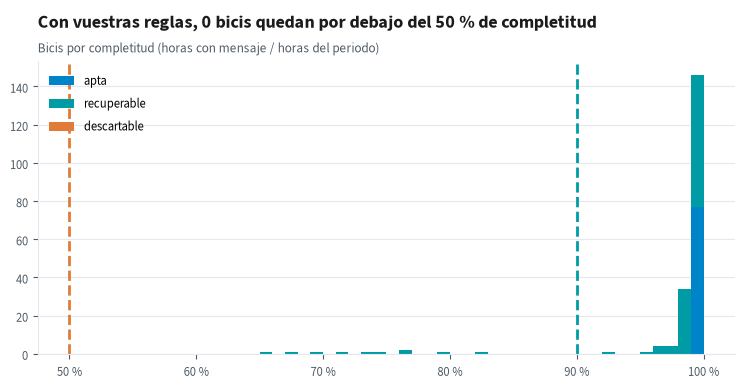

In [15]:
bajas = (informe["completitud"] < completitud_descartable).sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
colores = {"apta": estilo.AZUL, "recuperable": estilo.TURQUESA, "descartable": estilo.NARANJA}
bordes = np.linspace(0.6, 1.0, 41)
ax.hist([informe.loc[informe["clase"] == c, "completitud"].clip(lower=0.6) for c in colores],
        bins=bordes, stacked=True, color=list(colores.values()), label=list(colores))
ax.axvline(completitud_descartable, color=estilo.NARANJA, linestyle="--")
ax.axvline(completitud_recuperable, color=estilo.TURQUESA, linestyle="--")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0)))
ax.legend(loc="upper left")
ax.set_title(f"Con vuestras reglas, {bajas} bicis quedan por debajo del {pct(completitud_descartable, 0)} de completitud")
estilo.subtitulo(ax, "Bicis por completitud (horas con mensaje / horas del periodo)")
plt.show()

## Qué os lleváis

- Toda telemetría trae seis defectos de serie: huecos, duplicados, filas fuera de orden,
  reinicios, bicis paradas y valores imposibles. Se buscan siempre, de forma sistemática.
- Antes de diferenciar un acumulado: ordenar, quitar duplicados, mirar el tiempo entre lecturas
  y tratar aparte los saltos negativos.
- Guarda en UTC y enseña en hora local. Un lote con el reloj cambiado solo se ve al comparar perfiles.
- Imputa solo si puedes decir qué imputaste: **un indicador de calidad por registro vale más que
  una limpieza silenciosa.**